In [3]:
!pip -q install nltk scikit-learn pandas matplotlib seaborn ipywidgets


[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully.")

[nltk_data] Error loading stopwords: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>
[nltk_data] Error loading wordnet: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>


Libraries imported successfully.


[nltk_data] Error loading omw-1.4: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>


In [5]:
corpus = {
    "diabetes_basics": [
        "What is diabetes?",
        "Explain the meaning of diabetes mellitus.",
        "What are the different types of diabetes?",
        "What is the difference between type 1 and type 2 diabetes?",
        "Why does diabetes develop?",
        "Can family history increase diabetes risk?",
        "What is gestational diabetes?",
        "How does insulin relate to diabetes?",
        "Who is at risk of developing type 2 diabetes?",
        "Can diabetes affect the body's organs?"
    ],
    "diabetes_symptoms": [
        "What are the common symptoms of diabetes?",
        "Why do people with diabetes feel very thirsty?",
        "Is frequent urination a sign of diabetes?",
        "Can unexplained weight loss be related to diabetes?",
        "Why does diabetes cause increased hunger?",
        "Can blurred vision occur with high blood sugar?",
        "Does diabetes cause tiredness and fatigue?",
        "What are the early warning signs of diabetes?",
        "Can slow wound healing be associated with diabetes?",
        "What symptoms can occur when blood glucose is high?"
    ],
    "blood_glucose": [
        "How can I check my blood sugar at home?",
        "What is a blood glucose meter?",
        "When should blood glucose be tested?",
        "What is a fasting blood sugar test?",
        "What does an HbA1c test measure?",
        "How is continuous glucose monitoring used?",
        "Why should glucose readings be recorded?",
        "What is the purpose of a post meal glucose test?",
        "How do I use a glucose testing strip?",
        "Why is regular blood sugar monitoring important?"
    ],
    "diet_nutrition": [
        "What foods are suitable for people with diabetes?",
        "Can a person with diabetes eat rice?",
        "Which fruits can be included in a diabetes diet?",
        "Why should carbohydrate intake be monitored?",
        "What is a balanced meal for diabetes?",
        "Are sugary drinks suitable for people with diabetes?",
        "How does fibre affect blood sugar?",
        "Should people with diabetes skip meals?",
        "What are healthy snack choices for diabetes?",
        "How can portion control help manage diabetes?"
    ],
    "exercise_lifestyle": [
        "What exercises are helpful for diabetes?",
        "How does walking affect blood glucose?",
        "How much physical activity is generally recommended?",
        "Can exercise improve insulin sensitivity?",
        "Why is maintaining a healthy weight important?",
        "Can poor sleep affect blood sugar?",
        "How does stress influence glucose levels?",
        "What lifestyle changes can help manage diabetes?",
        "Should I check glucose around exercise?",
        "Why is regular physical activity important for diabetes?"
    ],
    "medication": [
        "What is insulin used for?",
        "What are common types of diabetes medication?",
        "How does metformin help manage type 2 diabetes?",
        "Why might a person with diabetes need insulin?",
        "What is the difference between insulin and tablets?",
        "Can diabetes medication cause low blood sugar?",
        "Why is it important to take prescribed medicine regularly?",
        "What should I ask my doctor about diabetes medication?",
        "Are insulin injections used in diabetes care?",
        "Can I change my diabetes medicine dose myself?"
    ]
}

records = [
    {"query": query, "intent": intent}
    for intent, queries in corpus.items()
    for query in queries
]
df = pd.DataFrame(records)

print("Total queries:", len(df))
print("\nQueries per intent:")
print(df["intent"].value_counts())
display(df.head(10))

Total queries: 60

Queries per intent:
intent
diabetes_basics       10
diabetes_symptoms     10
blood_glucose         10
diet_nutrition        10
exercise_lifestyle    10
medication            10
Name: count, dtype: int64


,query,intent
0,What is diabetes?,diabetes_basics
1,Explain the meaning of diabetes mellitus.,diabetes_basics
2,What are the different types of diabetes?,diabetes_basics
3,What is the difference between type 1 and type...,diabetes_basics
4,Why does diabetes develop?,diabetes_basics
5,Can family history increase diabetes risk?,diabetes_basics
6,What is gestational diabetes?,diabetes_basics
7,How does insulin relate to diabetes?,diabetes_basics
8,Who is at risk of developing type 2 diabetes?,diabetes_basics
9,Can diabetes affect the body's organs?,diabetes_basics


In [6]:
taxonomy = {
    "Diabetes Basics": {
        "Types": ["Type 1 diabetes", "Type 2 diabetes", "Gestational diabetes"],
        "Causes and Risk Factors": ["Family history", "Insulin resistance", "Lifestyle factors"]
    },
    "Diabetes Symptoms": {
        "Common Symptoms": ["Increased thirst", "Frequent urination", "Increased hunger"],
        "Warning Signs": ["Blurred vision", "Unexplained weight loss", "Slow wound healing"]
    },
    "Blood Glucose": {
        "Testing Methods": ["Blood glucose meter", "HbA1c test", "Continuous glucose monitor"],
        "Monitoring Practices": ["Fasting measurement", "Post-meal measurement", "Recording readings"]
    },
    "Diet and Nutrition": {
        "Food Groups": ["Whole grains", "Vegetables", "Fruits and protein"],
        "Meal Planning": ["Carbohydrate awareness", "Portion control", "Balanced meals"]
    },
    "Exercise and Lifestyle": {
        "Physical Activity": ["Walking", "Aerobic activity", "Strength exercises"],
        "Lifestyle Habits": ["Sleep", "Stress management", "Weight management"]
    },
    "Medication": {
        "Medication Types": ["Insulin", "Metformin", "Other prescribed medicines"],
        "Medication Safety": ["Following prescriptions", "Side effects", "Clinical consultation"]
    }
}

for major, subcategories in taxonomy.items():
    print("\n" + major)
    for sub, concepts in subcategories.items():
        print("  ├──", sub, ":", ", ".join(concepts))


Diabetes Basics
  ├── Types : Type 1 diabetes, Type 2 diabetes, Gestational diabetes
  ├── Causes and Risk Factors : Family history, Insulin resistance, Lifestyle factors

Diabetes Symptoms
  ├── Common Symptoms : Increased thirst, Frequent urination, Increased hunger
  ├── Warning Signs : Blurred vision, Unexplained weight loss, Slow wound healing

Blood Glucose
  ├── Testing Methods : Blood glucose meter, HbA1c test, Continuous glucose monitor
  ├── Monitoring Practices : Fasting measurement, Post-meal measurement, Recording readings

Diet and Nutrition
  ├── Food Groups : Whole grains, Vegetables, Fruits and protein
  ├── Meal Planning : Carbohydrate awareness, Portion control, Balanced meals

Exercise and Lifestyle
  ├── Physical Activity : Walking, Aerobic activity, Strength exercises
  ├── Lifestyle Habits : Sleep, Stress management, Weight management

Medication
  ├── Medication Types : Insulin, Metformin, Other prescribed medicines
  ├── Medication Safety : Following prescript

In [7]:
domain_concepts = [
    "Diabetes", "Insulin", "Blood Glucose", "Pancreas",
    "Insulin Resistance", "HbA1c", "Diet", "Exercise",
    "Medication", "Glucose Meter", "Type 1 Diabetes",
    "Type 2 Diabetes", "Complications", "Healthcare Professional"
]

relationships = [
    ("Type 1 Diabetes", "is a type of", "Diabetes"),
    ("Type 2 Diabetes", "is a type of", "Diabetes"),
    ("Diabetes", "involves regulation of", "Blood Glucose"),
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "helps regulate", "Blood Glucose"),
    ("Insulin Resistance", "is associated with", "Type 2 Diabetes"),
    ("HbA1c", "provides information about", "Blood Glucose"),
    ("Glucose Meter", "measures", "Blood Glucose"),
    ("Diet", "can influence", "Blood Glucose"),
    ("Exercise", "can influence", "Blood Glucose"),
    ("Medication", "may be prescribed to manage", "Diabetes"),
    ("Diabetes", "may lead to", "Complications"),
    ("Healthcare Professional", "provides guidance about", "Medication"),
    ("Healthcare Professional", "interprets", "HbA1c")
]

print("Domain concepts:", len(domain_concepts))
print(*domain_concepts, sep=" | ")
print("\nRelationships:", len(relationships))
for subject, relation, obj in relationships:
    print(f"{subject} --{relation}--> {obj}")

Domain concepts: 14
Diabetes | Insulin | Blood Glucose | Pancreas | Insulin Resistance | HbA1c | Diet | Exercise | Medication | Glucose Meter | Type 1 Diabetes | Type 2 Diabetes | Complications | Healthcare Professional

Relationships: 14
Type 1 Diabetes --is a type of--> Diabetes
Type 2 Diabetes --is a type of--> Diabetes
Diabetes --involves regulation of--> Blood Glucose
Pancreas --produces--> Insulin
Insulin --helps regulate--> Blood Glucose
Insulin Resistance --is associated with--> Type 2 Diabetes
HbA1c --provides information about--> Blood Glucose
Glucose Meter --measures--> Blood Glucose
Diet --can influence--> Blood Glucose
Exercise --can influence--> Blood Glucose
Medication --may be prescribed to manage--> Diabetes
Diabetes --may lead to--> Complications
Healthcare Professional --provides guidance about--> Medication
Healthcare Professional --interprets--> HbA1c


In [8]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    tokens = re.findall(r"\b[a-z]+\b", text)
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]
    return tokens

sample = "People with Diabetes should monitor their blood glucose levels regularly."
print("Original:", sample)
print("Processed tokens:", preprocess_text(sample))

Original: People with Diabetes should monitor their blood glucose levels regularly.
Processed tokens: ['people', 'diabetes', 'monitor', 'blood', 'glucose', 'level', 'regularly']


In [9]:
X = df["query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    tokenizer=preprocess_text,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("TF-IDF training matrix:", X_train_tfidf.shape)
print("Model training completed.")

Training samples: 45
Testing samples: 15
TF-IDF training matrix: (45, 215)
Model training completed.


Accuracy : 0.4000
Precision: 0.3511
Recall   : 0.4000
F1-score : 0.3057

Classification Report:
                    precision    recall  f1-score   support

     blood_glucose       0.40      1.00      0.57         2
   diabetes_basics       0.33      0.50      0.40         2
 diabetes_symptoms       1.00      0.33      0.50         3
    diet_nutrition       0.00      0.00      0.00         3
exercise_lifestyle       0.00      0.00      0.00         3
        medication       0.40      1.00      0.57         2

          accuracy                           0.40        15
         macro avg       0.36      0.47      0.34        15
      weighted avg       0.35      0.40      0.31        15



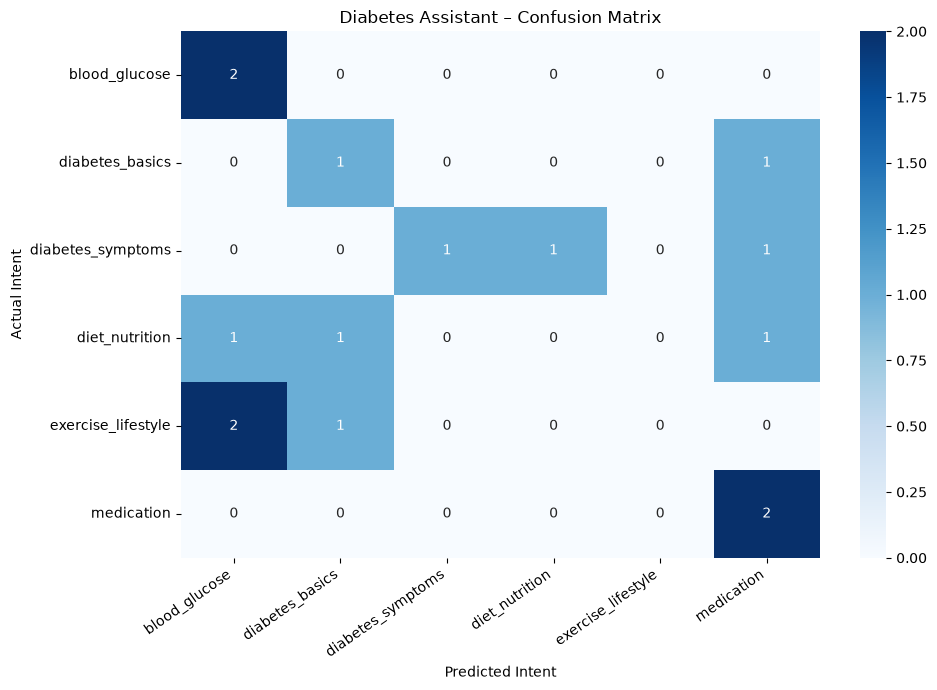

In [10]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df["intent"].unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Diabetes Assistant – Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
knowledge_base = {
    "diabetes_basics": (
        "Diabetes is a chronic condition in which blood glucose levels are elevated "
        "because the body does not produce enough insulin or cannot use insulin effectively. "
        "Major forms include type 1, type 2, and gestational diabetes. A healthcare "
        "professional can explain individual risk factors and appropriate testing."
    ),
    "diabetes_symptoms": (
        "Possible symptoms include increased thirst, frequent urination, increased hunger, "
        "fatigue, blurred vision, and unexplained weight changes. Some people, especially "
        "with type 2 diabetes, may have few or no noticeable symptoms. Testing by a "
        "healthcare professional is needed for diagnosis."
    ),
    "blood_glucose": (
        "Blood glucose can be monitored using a blood glucose meter, continuous glucose "
        "monitor, and laboratory tests such as HbA1c. The appropriate timing and target "
        "range depend on the individual. Follow the monitoring plan provided by your "
        "healthcare professional."
    ),
    "diet_nutrition": (
        "A balanced eating pattern may include vegetables, high-fibre foods, suitable "
        "protein sources, and appropriately portioned carbohydrate foods. Carbohydrate "
        "awareness and portion sizes can help with glucose management. Individual meal "
        "plans should be discussed with a registered dietitian or healthcare professional."
    ),
    "exercise_lifestyle": (
        "Regular physical activity, such as walking and other suitable aerobic or strength "
        "activities, can support general health and glucose management. Activity should "
        "be appropriate for the person's health and abilities. Ask a healthcare professional "
        "about exercise precautions, especially if using glucose-lowering medication."
    ),
    "medication": (
        "Diabetes treatment may include insulin or other prescribed medicines. The choice "
        "depends on diabetes type, health status, glucose levels, and clinical assessment. "
        "Take medicines as prescribed. Do not start, stop, or change a dose without advice "
        "from the prescribing healthcare professional."
    )
}

print("Knowledge base categories:", len(knowledge_base))
for intent in knowledge_base:
    print("-", intent)

Knowledge base categories: 6
- diabetes_basics
- diabetes_symptoms
- blood_glucose
- diet_nutrition
- exercise_lifestyle
- medication


In [12]:
EMERGENCY_KEYWORDS = [
    "unconscious", "passed out", "not responding",
    "seizure", "convulsion", "cannot breathe",
    "difficulty breathing", "chest pain",
    "severe confusion", "severe hypoglycemia"
]

MEDICATION_CHANGE_KEYWORDS = [
    "change my dose", "increase my dose", "decrease my dose",
    "stop my insulin", "stop taking my medicine",
    "double my dose", "skip my insulin"
]

SUPPORTED_KEYWORDS = {
    "diabetes_basics": [
        "diabetes", "type 1", "type 2", "gestational", "insulin resistance",
        "risk factor", "cause", "pancreas"
    ],
    "diabetes_symptoms": [
        "symptom", "thirst", "urination", "hunger", "fatigue",
        "tired", "blurred vision", "weight loss", "wound"
    ],
    "blood_glucose": [
        "blood sugar", "blood glucose", "glucose meter", "hba1c",
        "monitor", "testing", "test strip", "glucose reading"
    ],
    "diet_nutrition": [
        "food", "diet", "eat", "fruit", "vegetable", "rice",
        "carbohydrate", "sugar", "meal", "nutrition", "snack"
    ],
    "exercise_lifestyle": [
        "exercise", "walk", "walking", "physical activity", "sleep",
        "stress", "weight", "lifestyle", "fitness"
    ],
    "medication": [
        "medicine", "medication", "insulin", "metformin",
        "tablet", "dose", "injection", "drug"
    ]
}

def assistant_response(query, confidence_threshold=0.30):
    query_clean = query.lower().strip()

    if not query_clean:
        return "Please enter a question about diabetes care.", "empty_input", 0.0

    # Rule 1: Emergency escalation has highest priority.
    if any(term in query_clean for term in EMERGENCY_KEYWORDS):
        return (
            "EMERGENCY ALERT: This may describe a medical emergency. "
            "Call your local emergency number or seek emergency medical care immediately. "
            "Do not wait for this assistant. If the person is unconscious, having a seizure, "
            "or having difficulty breathing, get emergency help now.",
            "emergency", 1.0
        )

    # Rule 2: Medication dose changes must be referred to a clinician.
    if any(term in query_clean for term in MEDICATION_CHANGE_KEYWORDS):
        return (
            "Medication safety notice: Do not change, stop, or double diabetes medication "
            "or insulin doses based on this assistant. Contact your prescribing healthcare "
            "professional for individualized instructions. If you may have taken an incorrect "
            "dose or feel unwell, seek prompt medical advice.",
            "medication_safety", 1.0
        )

    # Rule 3: Reject queries with no identifiable diabetes-domain terms.
    all_domain_terms = [
        term for terms in SUPPORTED_KEYWORDS.values() for term in terms
    ]
    if not any(term in query_clean for term in all_domain_terms):
        return (
            "I can currently answer general questions about diabetes basics, symptoms, "
            "blood glucose monitoring, diet, exercise, and medication. Please ask a "
            "question related to one of these topics.",
            "unsupported", 0.0
        )

    # Classify the query.
    query_vector = tfidf.transform([query])
    probabilities = model.predict_proba(query_vector)[0]
    best_index = int(np.argmax(probabilities))
    predicted_intent = model.classes_[best_index]
    confidence = float(probabilities[best_index])

    # Rule 4: Low-confidence handling.
    if confidence < confidence_threshold:
        return (
            "I am not sufficiently confident about the intent of your question. "
            "Please rephrase it or ask about diabetes basics, symptoms, blood glucose, "
            "diet, exercise, or medication.",
            "low_confidence", confidence
        )

    # Rule 5: Knowledge retrieval and disclaimer.
    answer = knowledge_base[predicted_intent]
    answer += (
        "\n\nDisclaimer: This information is educational only. It is not a diagnosis "
        "or a substitute for professional medical advice."
    )

    return answer, predicted_intent, confidence


print("Rule engine and assistant response function are ready.")

Rule engine and assistant response function are ready.


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

query_box = widgets.Textarea(
    value="What is diabetes?\nHow can I monitor blood sugar?\nWhat foods are suitable for diabetes?",
    placeholder="Enter one question per line...",
    description="Queries:",
    layout=widgets.Layout(width="100%", height="130px")
)

run_button = widgets.Button(
    description="Get Responses",
    button_style="success",
    icon="check"
)

output_area = widgets.Output()

def process_queries(button):
    with output_area:
        clear_output()
        queries = [
            line.strip()
            for line in query_box.value.splitlines()
            if line.strip()
        ]

        if not queries:
            print("Please enter at least one query.")
            return

        for number, query in enumerate(queries, start=1):
            answer, intent, confidence = assistant_response(query)

            print("=" * 75)
            print(f"QUERY {number}: {query}")
            print(f"DETECTED INTENT: {intent}")
            print(f"CONFIDENCE: {confidence:.3f}")
            print("\nASSISTANT RESPONSE:")
            print(answer)
            print()

run_button.on_click(process_queries)
display(query_box, run_button, output_area)

Textarea(value='What is diabetes?\nHow can I monitor blood sugar?\nWhat foods are suitable for diabetes?', des…

Button(button_style='success', description='Get Responses', icon='check', style=ButtonStyle())

Output()

In [14]:
test_queries = [
    ("What is diabetes?", "Intent example", 0.30),
    ("Can you tell me about high blood sugar readings?", "Differently worded query", 0.30),
    ("How do I repair a bicycle?", "Unsupported query", 0.30),
    ("What is my exact personal diabetes treatment plan?", "Low-confidence query", 0.99),
    ("A person with diabetes is unconscious and having a seizure.", "Emergency query", 0.30),
    ("Can I double my insulin dose tonight?", "Medication safety query", 0.30)
]

for query, test_type, threshold in test_queries:
    answer, intent, confidence = assistant_response(
        query, confidence_threshold=threshold
    )
    print("\\nTEST TYPE:", test_type)
    print("QUERY:", query)
    print("RESULT:", intent)
    print("CONFIDENCE:", round(confidence, 3))
    print("RESPONSE:", answer[:350], "..." if len(answer) > 350 else "")
    print("-" * 75)

\nTEST TYPE: Intent example
QUERY: What is diabetes?
RESULT: diabetes_basics
CONFIDENCE: 0.322
RESPONSE: Diabetes is a chronic condition in which blood glucose levels are elevated because the body does not produce enough insulin or cannot use insulin effectively. Major forms include type 1, type 2, and gestational diabetes. A healthcare professional can explain individual risk factors and appropriate testing.

Disclaimer: This information is education ...
---------------------------------------------------------------------------
\nTEST TYPE: Differently worded query
QUERY: Can you tell me about high blood sugar readings?
RESULT: low_confidence
CONFIDENCE: 0.248
RESPONSE: I am not sufficiently confident about the intent of your question. Please rephrase it or ask about diabetes basics, symptoms, blood glucose, diet, exercise, or medication. 
---------------------------------------------------------------------------
\nTEST TYPE: Unsupported query
QUERY: How do I repair a bicycle?
RESUL